In [76]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/train.csv")
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [77]:
print(df.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


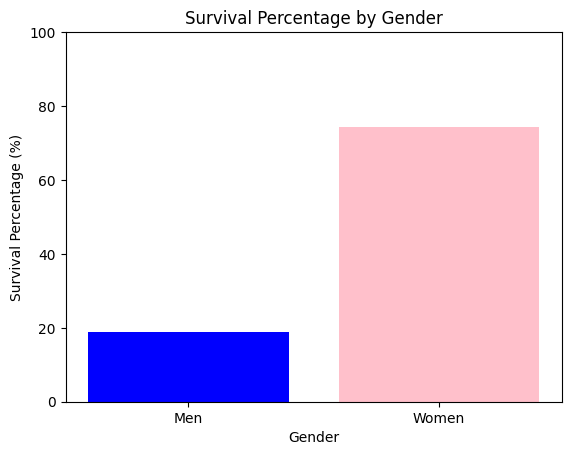

In [78]:
# Men
survived_men = df[(df["Sex"] == "male") & (df["Survived"] == 1)]
men_nbr = df[df["Sex"] == "male"]

num_survived_men = len(survived_men)
num_men = len(men_nbr)

# Women
survived_women = df[(df["Sex"] == "female") & (df["Survived"] == 1)]
women_nbr = df[df["Sex"] == "female"]

num_survived_women = len(survived_women)
num_women = len(women_nbr)

# Calculate percentages
men_percent = num_survived_men / num_men * 100
women_percent = num_survived_women / num_women * 100

genders = ["Men", "Women"]
percentages = [men_percent, women_percent]

# Plot
plt.bar(genders, percentages, color=["blue", "pink"])
plt.xlabel("Gender")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Gender")
plt.ylim(0, 100)
plt.show()


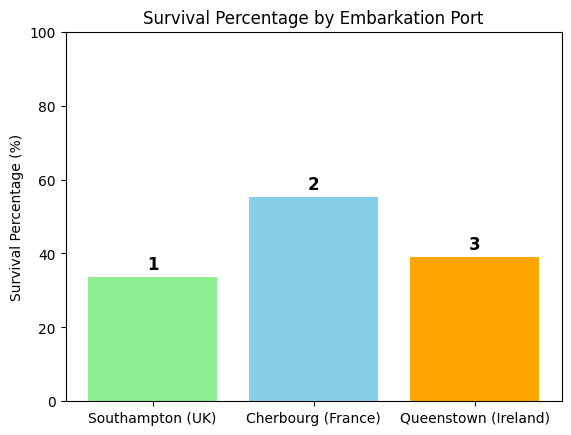

In [79]:
# Chronological order of Titanic's route
embarked_points = ["S", "C", "Q"]
embarked_map = {"C": "Cherbourg (France)", "Q": "Queenstown (Ireland)", "S": "Southampton (UK)"}

percentages = []

# Calculate survival percentage in order
for port in embarked_points:
    total = len(df[df["Embarked"] == port])
    survived = len(df[(df["Embarked"] == port) & (df["Survived"] == 1)])
    percentages.append(survived / total * 100)

# Labels for x-axis
labels = [embarked_map[port] for port in embarked_points]

# Chronology numbers
chronology = [1, 2, 3]  # Southampton=1, Cherbourg=2, Queenstown=3

# Plot
fig, ax = plt.subplots()
bars = ax.bar(labels, percentages, color=["lightgreen", "skyblue", "orange"])
ax.set_ylabel("Survival Percentage (%)")
ax.set_title("Survival Percentage by Embarkation Port")
ax.set_ylim(0, 100)

# Add chronology number on top of each bar
for bar, order in zip(bars, chronology):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        str(order),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.show()

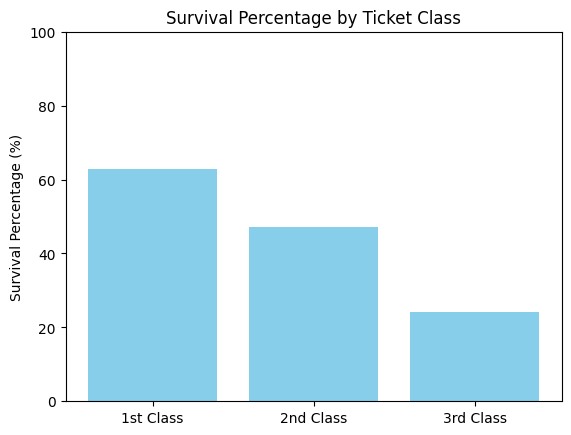

In [80]:
# Ticket classes
classes = [1, 2, 3]

# Calculate survival percentages
percentages = [
    len(df[(df["Pclass"] == cls) & (df["Survived"] == 1)]) / len(df[df["Pclass"] == cls]) * 100
    for cls in classes
]

# Plot
plt.bar(["1st Class", "2nd Class", "3rd Class"], percentages, color="skyblue")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Ticket Class")
plt.ylim(0, 100)



plt.show()

In [81]:
# Unique numbers for SibSp (siblings/spouses)
unique_sibsp = sorted(df["SibSp"].unique())
print("Unique SibSp values:", unique_sibsp)

# Unique numbers for Parch (parents/children)
unique_parch = sorted(df["Parch"].unique())
print("Unique Parch values:", unique_parch)


Unique SibSp values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(8)]
Unique Parch values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


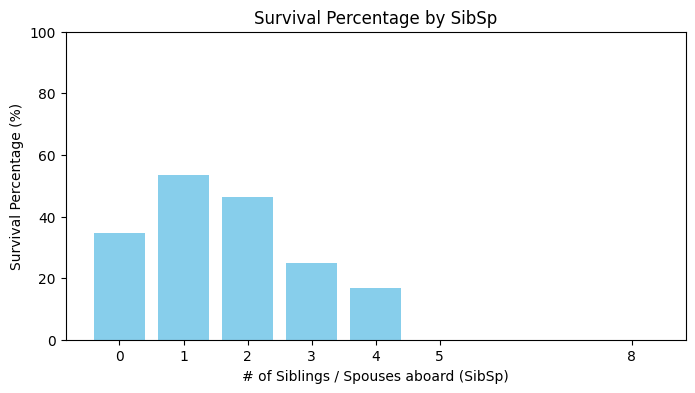

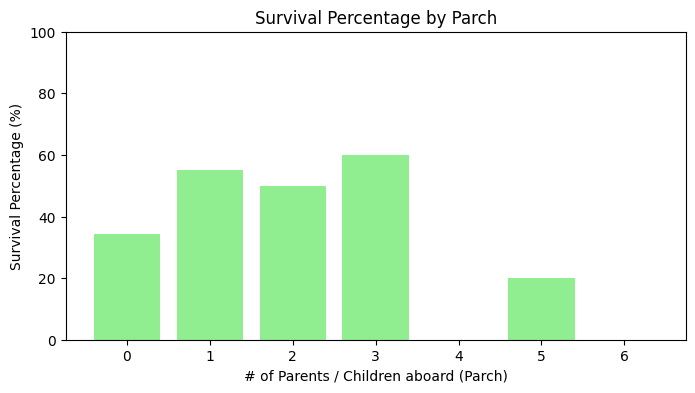

In [82]:

# --- Survival percentage by SibSp ---
sibsp_total = df.groupby("SibSp")["Survived"].count()
sibsp_survived = df.groupby("SibSp")["Survived"].sum()

sibsp_percent = sibsp_survived / sibsp_total * 100 

plt.figure(figsize=(8, 4))
plt.bar(sibsp_percent.index, sibsp_percent.values, color="skyblue")
plt.xlabel("# of Siblings / Spouses aboard (SibSp)")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by SibSp")
plt.ylim(0, 100)
plt.xticks(sibsp_percent.index)
plt.show()


# --- Survival percentage by Parch ---
parch_total = df.groupby("Parch")["Survived"].count()  
parch_survived = df.groupby("Parch")["Survived"].sum()

parch_percent = parch_survived / parch_total * 100 

plt.figure(figsize=(8, 4))
plt.bar(parch_percent.index, parch_percent.values, color="lightgreen")
plt.xlabel("# of Parents / Children aboard (Parch)")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Parch")
plt.ylim(0, 100)
plt.xticks(parch_percent.index)
plt.show()

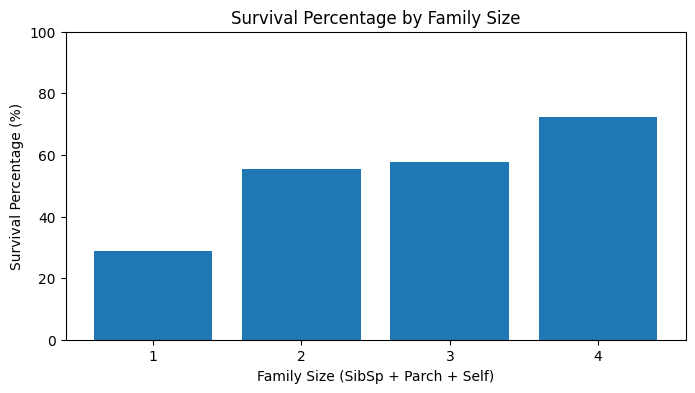

In [83]:
df["FamilyMembers"] = df["SibSp"] + df["Parch"]
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["FamilySize"] = df["FamilySize"].apply(lambda x: 1 if x > 4 else x)

family_total = df.groupby("FamilySize")["Survived"].count()
family_survived = df.groupby("FamilySize")["Survived"].sum()

family_percent = family_survived / family_total * 100

plt.figure(figsize=(8, 4))
plt.bar(family_percent.index, family_percent.values)
plt.xlabel("Family Size (SibSp + Parch + Self)")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Family Size")
plt.ylim(0, 100)
plt.xticks(family_percent.index)
plt.show()


/tmp/ipykernel_36123/1520898257.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_total = df.groupby("AgeGroup")["Survived"].count()
/tmp/ipykernel_36123/1520898257.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_survived = df.groupby("AgeGroup")["Survived"].sum()


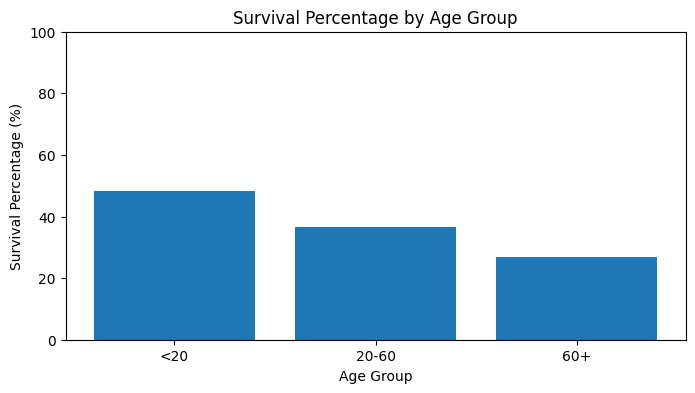

In [84]:
df["Age"] = df["Age"].fillna(df["Age"].median())
bins = [0, 20, 60, 100]
labels = ["<20", "20-60", "60+"]

df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)
age_total = df.groupby("AgeGroup")["Survived"].count()
age_survived = df.groupby("AgeGroup")["Survived"].sum()

age_percent = age_survived / age_total * 100

plt.figure(figsize=(8, 4))
plt.bar(age_percent.index, age_percent.values)
plt.xlabel("Age Group")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Age Group")
plt.ylim(0, 100)
plt.show()


/tmp/ipykernel_36123/2089947830.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_total = df.groupby("FareGroup")["Survived"].count()
/tmp/ipykernel_36123/2089947830.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_survived = df.groupby("FareGroup")["Survived"].sum()


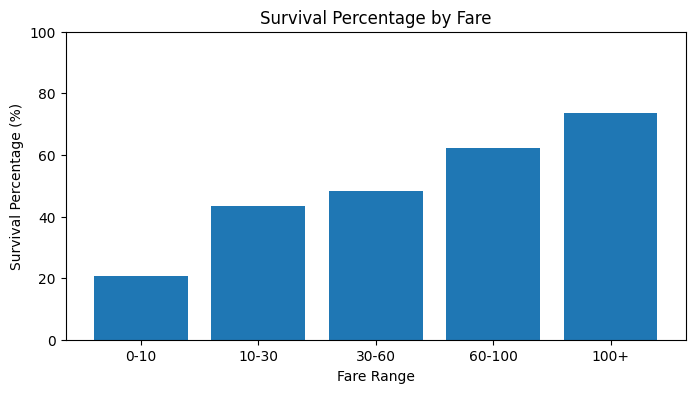

In [85]:
df["FareGroup"] = pd.cut(
    df["Fare"],
    bins=[0, 10, 30, 60, 100, 600],
    labels=["0-10", "10-30", "30-60", "60-100", "100+"]
)
fare_total = df.groupby("FareGroup")["Survived"].count()
fare_survived = df.groupby("FareGroup")["Survived"].sum()

fare_percent = fare_survived / fare_total * 100

plt.figure(figsize=(8, 4))
plt.bar(fare_percent.index, fare_percent.values)
plt.xlabel("Fare Range")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Fare")
plt.ylim(0, 100)
plt.show()



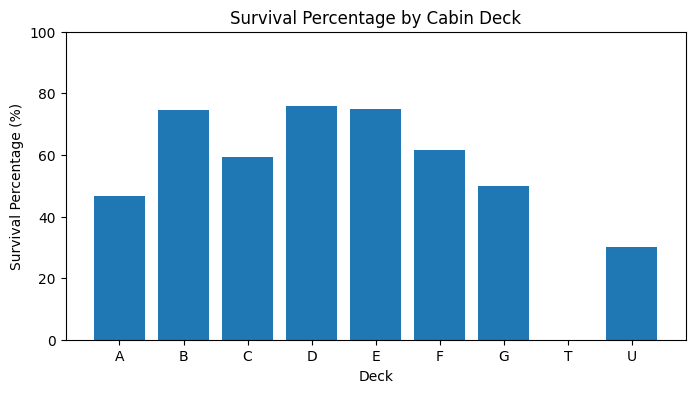

In [86]:
df["Cabin"] = df["Cabin"].fillna("Unknown")
df["Deck"] = df["Cabin"].str[0]
deck_total = df.groupby("Deck")["Survived"].count()
deck_survived = df.groupby("Deck")["Survived"].sum()

deck_percent = deck_survived / deck_total * 100

plt.figure(figsize=(8, 4))
plt.bar(deck_percent.index, deck_percent.values)
plt.xlabel("Deck")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Cabin Deck")
plt.ylim(0, 100)
plt.show()


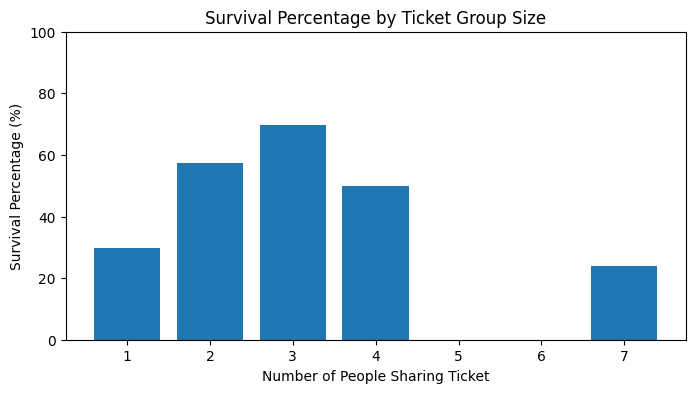

In [87]:
df["TicketGroupSize"] = df.groupby("Ticket")["Ticket"].transform("count")
ticket_total = df.groupby("TicketGroupSize")["Survived"].count()
ticket_survived = df.groupby("TicketGroupSize")["Survived"].sum()

ticket_percent = ticket_survived / ticket_total * 100
plt.figure(figsize=(8, 4))
plt.bar(ticket_percent.index, ticket_percent.values)
plt.xlabel("Number of People Sharing Ticket")
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Ticket Group Size")
plt.ylim(0, 100)
plt.show()


In [88]:
# Titanic Analysis Summary in Bullet Points
summary = [
    "Most missing values are in Age (177), Cabin (687), and Embarked (2).",
    "Women survived more often than men.",
    "Higher passenger class increased survival chances (1st > 2nd > 3rd).",
    "Passenger names, tickets, and cabins had no effect.",
    "Combining SibSp and Parch into FamilySize shows that larger families survived more.",
    "Younger passengers had higher survival rates.",
    "Passengers who paid higher fares had higher survival rates."
]

print("Titanic Data Analysis Summary:\n")
for point in summary:
    print(f"• {point}")


Titanic Data Analysis Summary:

• Most missing values are in Age (177), Cabin (687), and Embarked (2).
• Women survived more often than men.
• Higher passenger class increased survival chances (1st > 2nd > 3rd).
• Passenger names, tickets, and cabins had no effect.
• Combining SibSp and Parch into FamilySize shows that larger families survived more.
• Younger passengers had higher survival rates.
• Passengers who paid higher fares had higher survival rates.


In [89]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Replace rare titles
df['Title'] = df['Title'].replace(
    ['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona'],
    'Rare'
)

# Map common titles to numeric categories (optional)
title_mapping = {'Mr':0, 'Miss':1, 'Mrs':2, 'Master':3, 'Rare':4}
df['TitleCat'] = df['Title'].map(title_mapping)

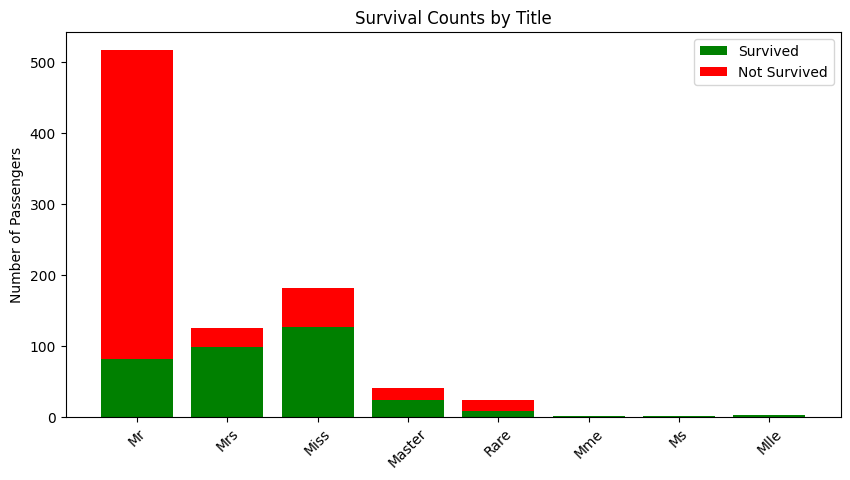

In [90]:
import matplotlib.pyplot as plt

# Compute counts
titles = df['Title'].unique()
survived_counts = []
not_survived_counts = []

for t in titles:
    survived_counts.append(df[(df['Title'] == t) & (df['Survived'] == 1)].shape[0])
    not_survived_counts.append(df[(df['Title'] == t) & (df['Survived'] == 0)].shape[0])

# Plot
x = range(len(titles))
plt.figure(figsize=(10,5))
plt.bar(x, survived_counts, label='Survived', color='green')
plt.bar(x, not_survived_counts, bottom=survived_counts, label='Not Survived', color='red')
plt.xticks(x, titles, rotation=45)
plt.ylabel("Number of Passengers")
plt.title("Survival Counts by Title")
plt.legend()
plt.show()


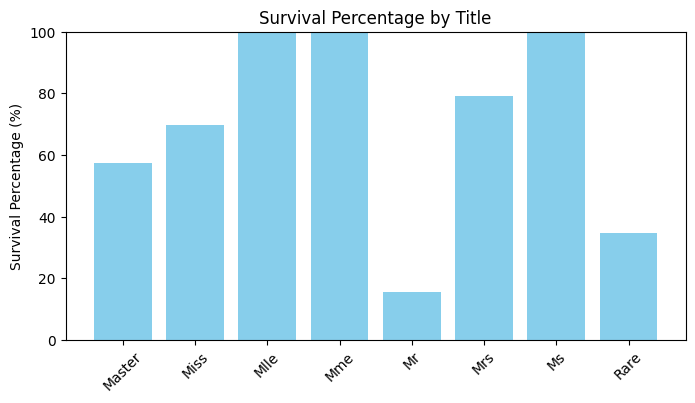

In [91]:
# Compute survival percentage
survival_percent = df.groupby('Title')['Survived'].mean() * 100

plt.figure(figsize=(8,4))
plt.bar(survival_percent.index, survival_percent.values, color='skyblue')
plt.ylabel("Survival Percentage (%)")
plt.title("Survival Percentage by Title")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.show()
